In [1]:
import pandas as pd

# Load the shortage data downloaded from S3
df = pd.read_csv("../data/shortage_clean.csv", dtype={"DIN": str})
print(df.shape)
df.head()

(10416, 22)


,REPORT_ID,DIN,REPORT_TYPE,BRAND_NAME,COMPANY_NAME,COMMON_NAME,INGREDIENTS,STRENGTH,PACKAGING_SIZE,ROUTE,...,ATC_CODE,ATC_DESCRIPTION,ANTICIPATED_START_DATE,ACTUAL_START_DATE,ESTIMATED_END_DATE,ACTUAL_END_DATE,REASON,DATE_CREATED,DATE_UPDATED,TIER_3
0,179915,00828602,Shortage,0.4% LIDOCAINE HYDROCHLORIDE AND 5% DEXTROSE I...,BAXTER CORPORATION,0.4% LIDOCAINE HYDROCHLORIDE AND 5% DEXTROSE I...,DEXTROSE; LIDOCAINE HYDROCHLORIDE,50MG; 4MG,500mL bag,INTRAVENOUS; INTRAVENOUS,...,C01BB,"ANTIARRHYTHMICS, CLASS I AND III",2023-01-09,2023-01-09,2023-02-13,2023-02-13,Demand increase for the drug.,2023-01-05,2023-02-14,No
1,236464,02395150,Shortage,0.9% SODIUM CHLORIDE INJECTION,FRESENIUS KABI CANADA LTD,0.9% SODIUM CHLORIDE INJECTION,SODIUM CHLORIDE,900MG,500 mL,INTRAVENOUS; INTRAVENOUS,...,B05XA,I.V. SOLUTION ADDITIVES,NaN,2024-09-03,2024-10-08,2024-10-08,Disruption of the manufacture of the drug.,2024-09-03,2024-10-09,No
2,241158,02395150,Shortage,0.9% SODIUM CHLORIDE INJECTION,FRESENIUS KABI CANADA LTD,0.9% SODIUM CHLORIDE INJECTION,SODIUM CHLORIDE,900MG,500 mL,INTRAVENOUS; INTRAVENOUS,...,B05XA,I.V. SOLUTION ADDITIVES,NaN,2024-10-28,2024-11-19,2024-11-19,Delay in shipping of the drug.,2024-10-25,2025-04-08,No
3,287084,02304341,Shortage,0.9% SODIUM CHLORIDE INJECTION USP,HIKMA CANADA LIMITED,0.9% SODIUM CHLORIDE INJECTION USP,SODIUM CHLORIDE,9MG,10mL,SUBCUTANEOUS; INTRAVENOUS; INTRAMUSCULAR; SUBC...,...,V07AB,ALL OTHER NON-THERAPEUTIC PRODUCTS,2026-07-01,2026-07-01,NaN,NaN,Disruption of the manufacture of the drug.,2026-06-12,2026-07-03,No
4,234265,00060208,Shortage,"0.9% SODIUM CHLORIDE INJECTION, USP",BAXTER CORPORATION,"0.9% SODIUM CHLORIDE INJECTION, USP",SODIUM CHLORIDE,900MG,JB0042 (50 mL),INTRAVENOUS; INTRAVENOUS,...,B05XA,I.V. SOLUTION ADDITIVES,2024-07-23,2024-07-23,2024-12-16,2024-12-11,Disruption of the manufacture of the drug.,2024-08-01,2024-12-12,No


In [2]:
# Convert date columns from text to real dates
date_cols = [
    "ANTICIPATED_START_DATE", "ACTUAL_START_DATE", "ESTIMATED_END_DATE",
    "ACTUAL_END_DATE", "DATE_CREATED", "DATE_UPDATED",
]
for col in date_cols:
    df[col] = pd.to_datetime(df[col])

# Keep resolved shortages that have both a start and an end date
resolved = df[
    (df["STATUS"] == "Resolved")
    & df["ACTUAL_START_DATE"].notna()
    & df["ACTUAL_END_DATE"].notna()
].copy()

# Duration of each shortage in days
resolved["DURATION_DAYS"] = (
    resolved["ACTUAL_END_DATE"] - resolved["ACTUAL_START_DATE"]
).dt.days

# Target: did the shortage last more than 90 days?
resolved["LONG_SHORTAGE"] = (resolved["DURATION_DAYS"] > 90).astype(int)

print("Resolved shortages with dates:", len(resolved))
print(resolved["DURATION_DAYS"].describe())
print()
print("Share of long shortages (> 90 days):")
print(resolved["LONG_SHORTAGE"].value_counts(normalize=True).round(3))

Resolved shortages with dates: 8408
count    8408.000000
mean       98.365723
std       142.767044
min         0.000000
25%        23.000000
50%        51.000000
75%       112.000000
max      2335.000000
Name: DURATION_DAYS, dtype: float64

Share of long shortages (> 90 days):
LONG_SHORTAGE
0    0.686
1    0.314
Name: proportion, dtype: float64


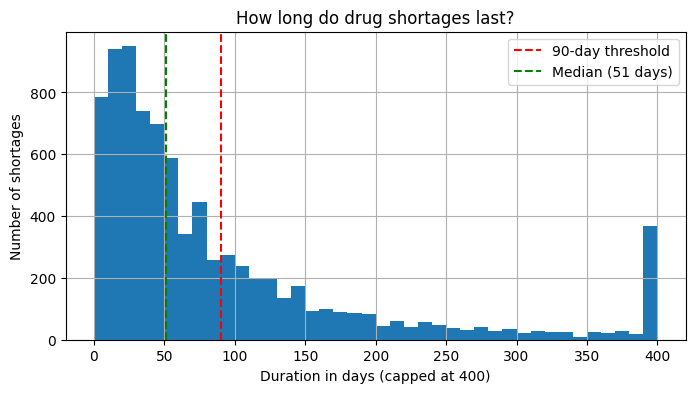

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))

# Cap at 400 days so the long tail does not squeeze the chart
resolved["DURATION_DAYS"].clip(upper=400).hist(bins=40, ax=ax)
ax.axvline(90, color="red", linestyle="--", label="90-day threshold")
ax.axvline(resolved["DURATION_DAYS"].median(), color="green",
           linestyle="--", label="Median (51 days)")

ax.set_title("How long do drug shortages last?")
ax.set_xlabel("Duration in days (capped at 400)")
ax.set_ylabel("Number of shortages")
ax.legend()
plt.show()

In [4]:
# Simplify a few columns into features that are easier to compare
resolved["ATC_GROUP"] = resolved["ATC_CODE"].str[0]  # first letter = main drug group
resolved["MAIN_ROUTE"] = resolved["ROUTE"].str.split(";").str[0].str.strip()


def long_rate(column, min_count=50):
    """Share of long shortages for each value of a column (only common values)."""
    summary = (
        resolved.groupby(column)["LONG_SHORTAGE"]
        .agg(count="count", long_rate="mean")
        .query("count >= @min_count")
        .sort_values("long_rate", ascending=False)
    )
    summary["long_rate"] = summary["long_rate"].round(3)
    return summary


print("=== By reason ===")
print(long_rate("REASON"))
print("\n=== By Tier 3 ===")
print(long_rate("TIER_3"))
print("\n=== By main route ===")
print(long_rate("MAIN_ROUTE"))
print("\n=== By ATC group ===")
print(long_rate("ATC_GROUP"))

=== By reason ===
                                                    count  long_rate
REASON                                                              
Shortage of an active ingredient.                      80      0.550
Requirements related to complying with good man...    240      0.492
Other (Please describe in comments)                   419      0.346
Disruption of the manufacture of the drug.           5706      0.326
Demand increase for the drug.                        1187      0.296
Delay in shipping of the drug.                        730      0.137

=== By Tier 3 ===
        count  long_rate
TIER_3                  
No       8393      0.313

=== By main route ===
               count  long_rate
MAIN_ROUTE                     
INTRAMUSCULAR     94      0.362
TOPICAL          307      0.358
ORAL            6078      0.321
INHALATION       107      0.318
INTRAVENOUS      844      0.297
OPHTHALMIC       227      0.264
SUBCUTANEOUS     268      0.246
NASAL             61     

## Key findings from exploration

- 8,408 resolved shortages have both start and end dates. Median duration is 51 days, but the distribution is right-skewed (mean 98 days, max 2,335 days).
- 31.4% of shortages lasted more than 90 days. This is the target for the model.
- **Reason is the strongest signal.** Shortages caused by an active ingredient shortage (55%) or GMP compliance issues (49%) are much more likely to last over 90 days. Shipping delays rarely do (14%).
- **Route matters somewhat.** Long shortages range from 17% (transdermal) to 36% (intramuscular).
- ATC drug group shows only small differences (26% to 34%).
- Tier 3 is almost always "No" among resolved shortages (15 of 8,408), so it is not useful as a feature.

In [5]:
# Sort all reports by the date they were created, so each report only "sees" earlier ones
history = df.sort_values("DATE_CREATED").copy()

# How many earlier shortage reports exist for the same ingredient / company
history["ING_PRIOR_REPORTS"] = history.groupby("INGREDIENTS").cumcount()
history["COMPANY_PRIOR_REPORTS"] = history.groupby("COMPANY_NAME").cumcount()

# How many different companies have reported this ingredient so far
# (a rough proxy for how many alternative suppliers exist)
is_new_pair = ~history.duplicated(["INGREDIENTS", "COMPANY_NAME"])
history["ING_N_COMPANIES"] = is_new_pair.astype(int).groupby(history["INGREDIENTS"]).cumsum()

# Was the shortage reported in advance (an anticipated start date was given)?
history["REPORTED_IN_ADVANCE"] = history["ANTICIPATED_START_DATE"].notna().astype(int)

# Add the new features to the resolved shortages
history_cols = [
    "REPORT_ID", "ING_PRIOR_REPORTS", "COMPANY_PRIOR_REPORTS",
    "ING_N_COMPANIES", "REPORTED_IN_ADVANCE",
]
resolved = resolved.merge(history[history_cols], on="REPORT_ID", how="left")

# Quick check: long-shortage rate by number of alternative companies
resolved["N_COMPANIES_BUCKET"] = pd.cut(
    resolved["ING_N_COMPANIES"], bins=[0, 1, 3, 6, 100],
    labels=["1", "2-3", "4-6", "7+"],
)
print(long_rate("N_COMPANIES_BUCKET"))
print()
print(long_rate("REPORTED_IN_ADVANCE"))

                    count  long_rate
N_COMPANIES_BUCKET                  
4-6                  2316      0.331
7+                   1475      0.322
2-3                  2651      0.320
1                    1951      0.278

                     count  long_rate
REPORTED_IN_ADVANCE                  
0                     7218      0.319
1                     1190      0.287


C:\Users\wx080\AppData\Local\Temp\ipykernel_9868\3171361067.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  resolved.groupby(column)["LONG_SHORTAGE"]


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical = ["REASON", "MAIN_ROUTE", "ATC_GROUP", "COMPANY_NAME"]
numeric = ["ING_PRIOR_REPORTS", "COMPANY_PRIOR_REPORTS", "ING_N_COMPANIES", "REPORTED_IN_ADVANCE"]

# Fill missing values: unknown categories become "UNKNOWN", missing counts become 0
resolved[categorical] = resolved[categorical].fillna("UNKNOWN")
resolved[numeric] = resolved[numeric].fillna(0)

# Time-based split: train on earlier shortages, test on the most recent 20%
data = resolved.sort_values("ACTUAL_START_DATE").reset_index(drop=True)
cutoff = int(len(data) * 0.8)
train, test = data.iloc[:cutoff], data.iloc[cutoff:]
X_train, y_train = train[categorical + numeric], train["LONG_SHORTAGE"]
X_test, y_test = test[categorical + numeric], test["LONG_SHORTAGE"]
print(f"Train: {len(train)} rows, start dates up to {train['ACTUAL_START_DATE'].max().date()}")
print(f"Test:  {len(test)} rows, long-shortage rate in test = {y_test.mean():.3f}")

# Preprocessing: one-hot encode text columns, scale numeric columns
preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20), categorical),
    ("num", StandardScaler(), numeric),
])

model = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced")),
])
model.fit(X_train, y_train)

# Evaluate against a simple baseline that always predicts "not long"
proba = model.predict_proba(X_test)[:, 1]
pred = model.predict(X_test)
print(f"\nBaseline accuracy (always predict 0): {1 - y_test.mean():.3f}")
print(f"Model accuracy: {accuracy_score(y_test, pred):.3f}")
print(f"Model ROC AUC:  {roc_auc_score(y_test, proba):.3f}  (0.5 = random guessing)")
print()
print(classification_report(y_test, pred, digits=3))

Train: 6726 rows, start dates up to 2025-10-15
Test:  1682 rows, long-shortage rate in test = 0.214

Baseline accuracy (always predict 0): 0.786
Model accuracy: 0.629
Model ROC AUC:  0.678  (0.5 = random guessing)

              precision    recall  f1-score   support

           0      0.880     0.611     0.721      1322
           1      0.327     0.694     0.445       360

    accuracy                          0.629      1682
   macro avg      0.604     0.653     0.583      1682
weighted avg      0.762     0.629     0.662      1682



In [8]:
from sklearn.ensemble import HistGradientBoostingClassifier

# Tree models do not need scaling; they also need dense input
preprocess_tree = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20,
                          sparse_output=False), categorical),
    ("num", "passthrough", numeric),
])

gb_model = Pipeline([
    ("prep", preprocess_tree),
    ("clf", HistGradientBoostingClassifier(class_weight="balanced", random_state=42)),
])
gb_model.fit(X_train, y_train)

gb_proba = gb_model.predict_proba(X_test)[:, 1]
gb_pred = gb_model.predict(X_test)
print(f"Logistic regression ROC AUC: {roc_auc_score(y_test, proba):.3f}")
print(f"Gradient boosting ROC AUC:   {roc_auc_score(y_test, gb_proba):.3f}")
print()
print(classification_report(y_test, gb_pred, digits=3))

Logistic regression ROC AUC: 0.678
Gradient boosting ROC AUC:   0.691

              precision    recall  f1-score   support

           0      0.849     0.751     0.797      1322
           1      0.359     0.511     0.422       360

    accuracy                          0.700      1682
   macro avg      0.604     0.631     0.609      1682
weighted avg      0.744     0.700     0.717      1682



In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score

rf_model = Pipeline([
    ("prep", ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20), categorical),
        ("num", "passthrough", numeric),
    ])),
    ("clf", RandomForestClassifier(
        n_estimators=400,        # number of trees
        min_samples_leaf=5,      # each leaf needs at least 5 samples, reduces overfitting
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,               # use all CPU cores
    )),
])
rf_model.fit(X_train, y_train)


def evaluate(name, fitted_model):
    """Collect the main metrics for one model on the test set."""
    proba = fitted_model.predict_proba(X_test)[:, 1]
    pred = fitted_model.predict(X_test)
    return {
        "model": name,
        "roc_auc": roc_auc_score(y_test, proba),
        "accuracy": accuracy_score(y_test, pred),
        "recall_long": recall_score(y_test, pred),
        "precision_long": precision_score(y_test, pred),
    }


comparison = pd.DataFrame([
    evaluate("Logistic regression", model),
    evaluate("Gradient boosting", gb_model),
    evaluate("Random forest", rf_model),
]).round(3)

print(f"Baseline accuracy (always predict 0): {1 - y_test.mean():.3f}")
comparison

Baseline accuracy (always predict 0): 0.786


,model,roc_auc,accuracy,recall_long,precision_long
0,Logistic regression,0.678,0.629,0.694,0.327
1,Gradient boosting,0.691,0.700,0.511,0.359
2,Random forest,0.705,0.703,0.494,0.359
